# 01 — Pemahaman & Persiapan Data (Data Understanding)

## Tujuan
- Memahami struktur, dimensi, tipe data, dan kualitas dataset mentah Bondora (`LoanData.csv`).
- Mengidentifikasi duplikat, *missing values*, kolom konstan/berkardinalitas tinggi, distribusi numerik/kategorikal, dan rentang tanggal.
- Menyusun draf kamus data (`data_dictionary_draft.csv`) dan tabel *missing values* (`missing_values.csv`) sebagai dasar pengambilan keputusan pada **Gerbang 1** dan **Gerbang 2**.

## Input / Output
- **Input:** `data/raw/LoanData.csv` (bersifat *read-only*)
- **Output Bagian A:**
  - `reports/tables/missing_values.csv`
  - `reports/tables/data_dictionary_draft.csv`
  - `reports/figures/01_missing_values_histogram.png`

---
## Bagian A — Inspeksi Awal Dataset Mentah

### A.1 Setup & Dimensi Dataset
Memuat dataset menggunakan fungsi `load_raw()` dari `src.data.loader` dan memeriksa jumlah baris, jumlah kolom, serta konsumsi memori.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import (
    DATA_RAW,
    FIGURES_DIR,
    LOANDATA_FILENAME,
    RANDOM_SEED,
    TABLES_DIR,
    ensure_dirs,
)
from src.data.loader import describe_schema, load_raw

ensure_dirs()
df = load_raw()

n_rows, n_cols = df.shape
mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
file_size_mb = (DATA_RAW / LOANDATA_FILENAME).stat().st_size / (1024 * 1024)

print(f"Jumlah baris         : {n_rows:,}")
print(f"Jumlah kolom         : {n_cols}")
print(f"Ukuran file CSV (MB) : {file_size_mb:.2f} MB")
print(f"Ukuran memori DataFrame: {mem_mb:.2f} MB")

[load_raw] Successfully loaded 'LoanData.csv' using encoding='utf-8' (shape=179,235 rows x 112 cols).
Jumlah baris         : 179,235
Jumlah kolom         : 112
Ukuran file CSV (MB) : 142.66 MB
Ukuran memori DataFrame: 190.94 MB


### A.2 Daftar Kolom & Skema Awal (`describe_schema`)
Menampilkan seluruh kolom beserta tipe data (`dtype`), jumlah & persentase *missing*, jumlah nilai unik, dan 3 contoh nilai non-null pertama.

In [2]:
schema_df = describe_schema(df)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 160, "display.max_colwidth", 50):
    print(schema_df.to_string(index=False))

                            nama_kolom   dtype  n_missing  pct_missing  n_unique                                                                                                       contoh_nilai
                         ReportAsOfEOD     str          0       0.0000         1                                                                               2021-07-20 | 2021-07-20 | 2021-07-20
                                LoanId     str          0       0.0000    179235 66AE108B-532B-4BB3-BAB7-0019A46412C1 | D152382E-A50D-46ED-8FF2-0053E0C86A70 | 87342E13-66CB-483F-833A-007953E50C78
                            LoanNumber   int64          0       0.0000    179235                                                                                           483449 | 378148 | 451831
                           ListedOnUTC     str          0       0.0000    178456                                                    2016-03-23 16:07:19 | 2015-06-25 11:02:28 | 2016-01-14 10:00:21
                    

### A.3 Sampel Data: 5 Baris Pertama & 5 Baris Acak
Menampilkan 5 baris pertama (`df.head(5)`) dan 5 baris acak dengan `random_state=RANDOM_SEED` (`42`).

In [3]:
with pd.option_context("display.max_columns", 20, "display.width", 140):
    print("=== 5 Baris Pertama (df.head(5)) ===")
    print(df.head(5).to_string())
    print(f"\n=== 5 Baris Acak (df.sample(5, random_state={RANDOM_SEED})) ===")
    print(df.sample(5, random_state=RANDOM_SEED).to_string())

=== 5 Baris Pertama (df.head(5)) ===
  ReportAsOfEOD                                LoanId  LoanNumber          ListedOnUTC     BiddingStartedOn  BidsPortfolioManager  BidsApi  BidsManual   UserName  NewCreditCustomer LoanApplicationStartedDate    LoanDate ContractEndDate FirstPaymentDate MaturityDate_Original MaturityDate_Last  ApplicationSignedHour  ApplicationSignedWeekday  VerificationType  LanguageCode  Age  DateOfBirth  Gender Country  AppliedAmount  Amount  Interest  LoanDuration  MonthlyPayment  County  City  UseOfLoan  Education  MaritalStatus NrOfDependants  EmploymentStatus EmploymentDurationCurrentEmployer  EmploymentPosition   WorkExperience  OccupationArea  HomeOwnershipType  IncomeFromPrincipalEmployer  IncomeFromPension  IncomeFromFamilyAllowance  IncomeFromSocialWelfare  IncomeFromLeavePay  IncomeFromChildSupport  IncomeOther  IncomeTotal  ExistingLiabilities  LiabilitiesTotal  RefinanceLiabilities  DebtToIncome  FreeCash  MonthlyPaymentDay  ActiveScheduleFirstPaymentR

### A.4 Pemeriksaan Duplikat
Memeriksa: (a) baris yang identik penuh di seluruh kolom, dan (b) duplikat pada kandidat kolom pengenal (*identifier*).

In [4]:
n_full_dup = int(df.duplicated().sum())
print(f"(a) Jumlah baris duplikat identik penuh (df.duplicated().sum()): {n_full_dup:,}\n")
print("(b) Pemeriksaan kandidat kolom pengenal (ID):")
for col in df.columns:
    if any(k in col.lower() for k in ["id", "number", "username"]):
        n_miss = int(df[col].isna().sum())
        n_uniq = int(df[col].nunique(dropna=True))
        n_dup_nonnull = int(df[col].dropna().duplicated().sum())
        print(
            f"  - {col:<25}: dtype={df[col].dtype}, n_unique={n_uniq:,}, "
            f"n_missing={n_miss:,}, duplikat (non-null)={n_dup_nonnull:,}"
        )

(a) Jumlah baris duplikat identik penuh (df.duplicated().sum()): 0

(b) Pemeriksaan kandidat kolom pengenal (ID):
  - LoanId                   : dtype=str, n_unique=179,235, n_missing=0, duplikat (non-null)=0
  - LoanNumber               : dtype=int64, n_unique=179,235, n_missing=0, duplikat (non-null)=0
  - BiddingStartedOn         : dtype=str, n_unique=178,462, n_missing=0, duplikat (non-null)=773
  - BidsPortfolioManager     : dtype=int64, n_unique=5,803, n_missing=0, duplikat (non-null)=173,432
  - BidsApi                  : dtype=int64, n_unique=1,286, n_missing=0, duplikat (non-null)=177,949
  - BidsManual               : dtype=float64, n_unique=4,461, n_missing=0, duplikat (non-null)=174,774
  - UserName                 : dtype=str, n_unique=85,087, n_missing=0, duplikat (non-null)=94,148


### A.5 Analisis Missing Values
Mengurutkan kolom berdasarkan persentase *missing* tertinggi, menyimpan tabel ke `reports/tables/missing_values.csv`, dan menampilkan histogram distribusi persentase *missing*.

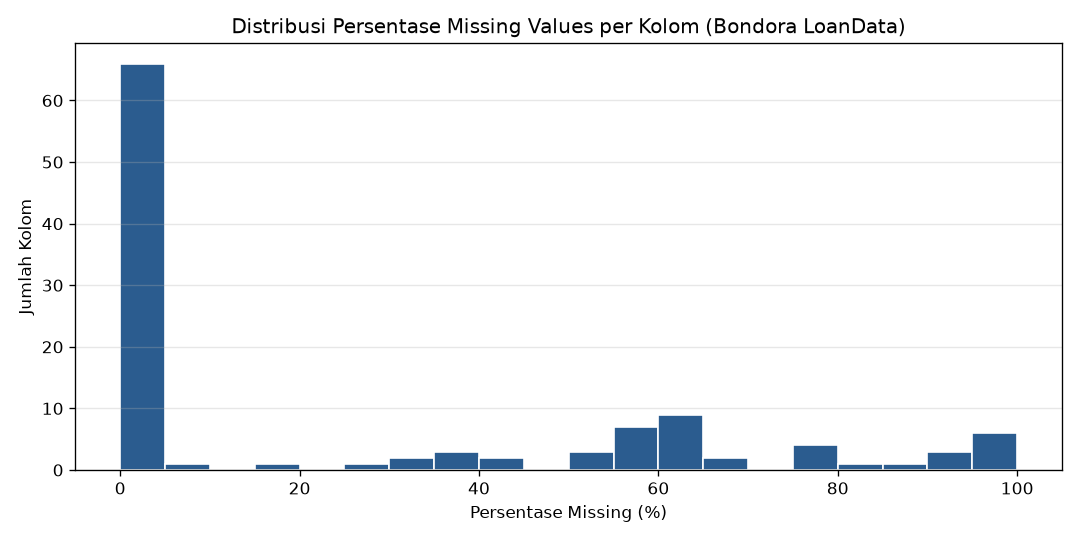

Disimpan ke: reports\tables\missing_values.csv
Total kolom dengan missing > 0%  : 69 dari 112 kolom
Kolom dengan missing > 50%       : 36 kolom
Kolom dengan missing > 80%       : 11 kolom
Kolom dengan missing > 90%       : 9 kolom
Kolom dengan missing > 95%       : 6 kolom

                            nama_kolom   dtype  n_missing  pct_missing  n_unique
                                  City float64     179235     100.0000         0
                                County float64     179235     100.0000         0
                           DateOfBirth float64     179235     100.0000         0
                    EmploymentPosition float64     179235     100.0000         0
                                 EL_V0 float64     174666      97.4508      1203
                             Rating_V0     str     174666      97.4508         8
              CreditScoreEsEquifaxRisk     str     167016      93.1827         6
                                 EL_V1 float64     166311      92.7894      1

In [5]:
missing_df = (
    schema_df[["nama_kolom", "dtype", "n_missing", "pct_missing", "n_unique"]]
    .sort_values(by=["pct_missing", "nama_kolom"], ascending=[False, True])
    .reset_index(drop=True)
)
missing_csv_path = TABLES_DIR / "missing_values.csv"
missing_df.to_csv(missing_csv_path, index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
ax.hist(missing_df["pct_missing"], bins=20, color="#2b5c8f", edgecolor="white")
ax.set_title("Distribusi Persentase Missing Values per Kolom (Bondora LoanData)")
ax.set_xlabel("Persentase Missing (%)")
ax.set_ylabel("Jumlah Kolom")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_missing_values_histogram.png")
plt.show()

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 140):
    print(f"Disimpan ke: {missing_csv_path.relative_to(project_root)}")
    print(f"Total kolom dengan missing > 0%  : {(missing_df['n_missing'] > 0).sum()} dari {n_cols} kolom")
    print(f"Kolom dengan missing > 50%       : {(missing_df['pct_missing'] > 50).sum()} kolom")
    print(f"Kolom dengan missing > 80%       : {(missing_df['pct_missing'] > 80).sum()} kolom")
    print(f"Kolom dengan missing > 90%       : {(missing_df['pct_missing'] > 90).sum()} kolom")
    print(f"Kolom dengan missing > 95%       : {(missing_df['pct_missing'] > 95).sum()} kolom\n")
    print(missing_df.to_string(index=False))

### A.6 Kolom Konstan & Kolom Berkardinalitas Sangat Tinggi
Mengidentifikasi kolom yang hanya memiliki $\le 1$ nilai unik (konstan) dan kolom dengan kardinalitas sangat tinggi ($> 1.000$ nilai unik).

In [6]:
const_cols = schema_df[schema_df["n_unique"] <= 1]
high_card_cols = schema_df[schema_df["n_unique"] > 1000].sort_values(by="n_unique", ascending=False)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 140):
    print(f"=== Kolom Konstan (n_unique <= 1): {len(const_cols)} kolom ===")
    print(const_cols.to_string(index=False) if len(const_cols) > 0 else "Tidak ada kolom dengan n_unique <= 1.")
    print(f"\n=== Kolom Berkardinalitas Sangat Tinggi (n_unique > 1.000): {len(high_card_cols)} kolom ===")
    print(high_card_cols.to_string(index=False))

=== Kolom Konstan (n_unique <= 1): 5 kolom ===
        nama_kolom   dtype  n_missing  pct_missing  n_unique                         contoh_nilai
     ReportAsOfEOD     str          0          0.0         1 2021-07-20 | 2021-07-20 | 2021-07-20
       DateOfBirth float64     179235        100.0         0                                     
            County float64     179235        100.0         0                                     
              City float64     179235        100.0         0                                     
EmploymentPosition float64     179235        100.0         0                                     

=== Kolom Berkardinalitas Sangat Tinggi (n_unique > 1.000): 59 kolom ===
                         nama_kolom   dtype  n_missing  pct_missing  n_unique                                                                                                       contoh_nilai
                             LoanId     str          0       0.0000    179235 66AE108B-532B-4BB3-B

### A.7 Statistik Deskriptif Kolom Numerik
Menghitung statistik deskriptif dengan persentil `1%, 5%, 25%, 50%, 75%, 95%, 99%` untuk seluruh kolom numerik.

In [7]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
desc_num = df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_num["n_missing"] = df[num_cols].isna().sum()
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 180, "display.float_format", "{:,.4f}".format):
    print(f"Jumlah kolom numerik: {len(num_cols)}\n")
    print(desc_num.to_string())

Jumlah kolom numerik: 74

                                              count           mean          std          min         1%           5%          25%            50%            75%            95%            99%             max  n_missing
LoanNumber                             179,235.0000 1,239,306.4402 661,026.5772      37.0000 5,326.3600 178,587.4000 712,538.0000 1,096,557.0000 1,851,458.5000 2,254,181.5000 2,302,680.9600  2,313,298.0000          0
BidsPortfolioManager                   179,235.0000       797.9625   1,235.5098       0.0000     0.0000       1.0000     105.0000       336.0000       960.0000     3,115.0000     6,220.0000     10,625.0000          0
BidsApi                                179,235.0000        27.4323     147.5683       0.0000     0.0000       0.0000       0.0000         0.0000         4.0000       110.0000       660.6600      7,570.0000          0
BidsManual                             179,235.0000       499.5448     714.7240       0.0000     0.0000   

### A.8 Tabel Frekuensi Kolom Kategorikal / Kode Berkardinalitas Rendah ($\le 30$ Nilai Unik)
Menampilkan distribusi nilai dan persentase (termasuk `NaN`) untuk setiap kolom bertipe teks/boolean/kode bulat dengan maksimal 30 nilai unik.

In [8]:
cat_candidate_cols = [
    col for col in df.columns
    if (not pd.api.types.is_float_dtype(df[col])) and 1 <= int(df[col].nunique(dropna=True)) <= 30
]
print(f"Jumlah kolom berkardinalitas rendah (<= 30 nilai unik, non-float): {len(cat_candidate_cols)}\n")
for col in cat_candidate_cols:
    vc = df[col].value_counts(dropna=False)
    pct = (vc / len(df) * 100).round(2)
    freq_df = pd.DataFrame({"count": vc, "pct (%)": pct})
    print(f"--- {col} (dtype={df[col].dtype}, n_unique={df[col].nunique(dropna=True)}) ---")
    print(freq_df.to_string())
    print()

Jumlah kolom berkardinalitas rendah (<= 30 nilai unik, non-float): 26

--- ReportAsOfEOD (dtype=str, n_unique=1) ---
                count  pct (%)
ReportAsOfEOD                 
2021-07-20     179235    100.0

--- NewCreditCustomer (dtype=bool, n_unique=2) ---
                    count  pct (%)
NewCreditCustomer                 
True               100402    56.02
False               78833    43.98

--- ApplicationSignedHour (dtype=int64, n_unique=24) ---
                       count  pct (%)
ApplicationSignedHour                
10                     14946     8.34
11                     14476     8.08
12                     14223     7.94
13                     13288     7.41
14                     13158     7.34
15                     12590     7.02
16                     11922     6.65
9                      11359     6.34
17                     10554     5.89
18                      9553     5.33
19                      8367     4.67
20                      7176     4.00
8       

### A.9 Inspeksi Kandidat Kolom Tanggal
Memeriksa rentang tanggal minimum–maksimum, jumlah *missing* awal, serta apakah ada nilai yang gagal di-*parse* sebagai tanggal.

In [9]:
date_candidate_cols = [
    "ReportAsOfEOD", "ListedOnUTC", "BiddingStartedOn", "LoanApplicationStartedDate",
    "LoanDate", "ContractEndDate", "FirstPaymentDate", "MaturityDate_Original",
    "MaturityDate_Last", "DateOfBirth", "LastPaymentOn", "DebtOccuredOn",
    "DebtOccuredOnForSecondary", "DefaultDate", "StageActiveSince",
    "GracePeriodStart", "GracePeriodEnd", "NextPaymentDate", "ReScheduledOn",
]
date_records = []
for col in date_candidate_cols:
    parsed = pd.to_datetime(df[col], errors="coerce", format="mixed")
    n_miss_raw = int(df[col].isna().sum())
    n_unparseable = int(parsed.isna().sum() - n_miss_raw)
    min_dt = parsed.min()
    max_dt = parsed.max()
    date_records.append({
        "nama_kolom": col,
        "dtype_awal": str(df[col].dtype),
        "n_missing_awal": n_miss_raw,
        "pct_missing_awal": round(n_miss_raw / len(df) * 100, 2),
        "n_gagal_parse": n_unparseable,
        "tanggal_min": str(min_dt) if pd.notna(min_dt) else "NaT",
        "tanggal_max": str(max_dt) if pd.notna(max_dt) else "NaT",
    })
date_df = pd.DataFrame(date_records)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 160):
    print(f"Jumlah kandidat kolom tanggal: {len(date_df)}\n")
    print(date_df.to_string(index=False))

Jumlah kandidat kolom tanggal: 19

                nama_kolom dtype_awal  n_missing_awal  pct_missing_awal  n_gagal_parse         tanggal_min         tanggal_max
             ReportAsOfEOD        str               0              0.00              0 2021-07-20 00:00:00 2021-07-20 00:00:00
               ListedOnUTC        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 20:53:22
          BiddingStartedOn        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 23:53:22
LoanApplicationStartedDate        str               0              0.00              0 2009-02-21 14:12:39 2021-07-19 22:38:21
                  LoanDate        str               0              0.00              0 2009-02-28 00:00:00 2021-07-19 00:00:00
           ContractEndDate        str           76239             42.54              0 2009-05-15 00:00:00 2027-06-28 00:00:00
          FirstPaymentDate        str               0              0.00     

### A.10 Penyimpanan Draf Kamus Data (`data_dictionary_draft.csv`)
Menyimpan tabel `reports/tables/data_dictionary_draft.csv` yang berisi ringkasan skema beserta kolom `deskripsi`, `kategori_waktu`, dan `peran` (diisi `TODO` untuk dikonfirmasi bersama pengguna).

---
## Bagian B — Definisi Target & Verifikasi Keputusan Gerbang 1 & 2 (Langkah 3)

### B.1 Pemeriksaan 448 Baris `Repaid` Tanpa `DefaultDate` dengan `PrincipalWriteOffs > 0`
Memeriksa distribusi `WorseLateCategory` dan nilai `PrincipalWriteOffs` pada 448 baris `Status == 'Repaid'` tanpa `DefaultDate` yang mengalami penghapusan buku pokok.

In [11]:
mask_448 = (df["Status"] == "Repaid") & df["DefaultDate"].isna() & (df["PrincipalWriteOffs"].fillna(0) > 0)
sub_448 = df[mask_448]
vc_448 = sub_448["WorseLateCategory"].value_counts(dropna=False)
pct_448 = (vc_448 / len(sub_448) * 100).round(2)
ge61_cats = ["61-90", "91-120", "121-150", "151-180", "180+"]
n_ge61 = int(sub_448["WorseLateCategory"].isin(ge61_cats).sum())
print(pd.DataFrame({"count": vc_448, "pct (%)": pct_448}))
print(f"\nProporsi keterlambatan >= 61 hari: {n_ge61}/{len(sub_448)} ({n_ge61/len(sub_448)*100:.2f}%)")
pw_448 = sub_448["PrincipalWriteOffs"]
print(f"PrincipalWriteOffs -> min={pw_448.min():.4f}, median={pw_448.median():.4f}, mean={pw_448.mean():.4f}, max={pw_448.max():.4f}")

=== Pemeriksaan 448 Baris Status=Repaid & DefaultDate Kosong dengan PrincipalWriteOffs > 0 ===
Jumlah baris: 448

Distribusi WorseLateCategory pada 448 baris tersebut:
                   count  pct (%)
WorseLateCategory                
180+                 354    79.02
61-90                 23     5.13
151-180               22     4.91
31-60                 21     4.69
121-150                9     2.01
8-15                   9     2.01
91-120                 6     1.34
16-30                  4     0.89

Proporsi dengan keterlambatan >= 61 hari: 414 / 448 = 92.41% (>= 90% TERPENUHI -> ditetapkan default = 1)
Ringkasan PrincipalWriteOffs (448 baris): min = 0.0100, median = 158.5450, mean = 498.7609, max = 9280.2400
297 baris Repaid tanpa DefaultDate yang hanya memiliki InterestAndPenaltyWriteOffs > 0 tetap default = 0.
Seluruh 745 baris tersebut ditandai pada kolom flag_repaid_ada_writeoff = True.


### B.2 Pembentukan Variabel Target (`default` [nullable `Int8`], `is_resolved`, `return_ratio`) & Tabel Ringkasan Target
- `default = 1` jika `DefaultDate` terisi (`71.416` baris) **ATAU** (`Status == 'Repaid'`, `DefaultDate` kosong, dan `PrincipalWriteOffs > 0` sebanyak `448` baris) $\rightarrow$ total positif `71.864` baris.
- `default = 0` dan `is_resolved = True` untuk `Status == 'Repaid'` tanpa `DefaultDate` dengan `PrincipalWriteOffs == 0` (`41.696` baris).
- `default = <NA>` (nullable `Int8`) dan `is_resolved = False` untuk `Status == 'Current'` (`57.611`) dan `Status == 'Late'` (`8.064`) tanpa `DefaultDate` (`65.675` baris *right-censored*).

In [12]:
from src.data.targets import make_default_label, make_is_resolved, make_regression_target

df = pd.concat([
    df,
    pd.DataFrame({
        "default": make_default_label(df),
        "is_resolved": make_is_resolved(df),
        "return_ratio": make_regression_target(df),
    }, index=df.index)
], axis=1)
target_summary_df = pd.read_csv(TABLES_DIR / "target_summary.csv")
print(f"default dtype: {df['default'].dtype}, notna: {int(df['default'].notna().sum()):,}, sum: {int(df['default'].sum()):,}, isna: {int(df['default'].isna().sum()):,}")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    print(target_summary_df.to_string(index=False))

Disimpan ke: reports\tables\target_summary.csv
Tipe data kolom default                     : Int8 (nullable integer)
Verifikasi default.notna().sum() (Resolved) : 113,560 baris (default.sum() = 71,864 positif [63.28%] + 41,696 negatif [36.72%])
Verifikasi default.isna().sum() (Censored)  : 65,675 baris (57,611 Current + 8,064 Late -> default = <NA>)
Verifikasi Total Seluruh Dataset            : 113,560 + 65,675 = 179,235 baris

                                                      kelompok                                                             aturan_perlakuan  n_baris  pct_dari_total  is_resolved  n_default_1  n_default_0  n_default_na  proporsi_default_pct loandate_min loandate_max  return_ratio_min  return_ratio_mean  return_ratio_median  return_ratio_max  return_ratio_pct_zero
                          1. DefaultDate terisi (Semua Status)                                                  is_resolved=True, default=1    71416           39.84         True        71416            0

---
## Bagian C — Pembersihan Dasar, Aturan Domain, Flag Anomali, & Indikator Missing (Langkah 4)

1. Konversi 18 kolom tanggal ke `datetime64[ns]` dan 15 kolom kategorikal ke `category` (`CreditScoreEeMini` dipertahankan sebagai `float64`).
2. Pengisian struktural berdasarkan aturan domain (perubahan pencatatan Bondora sejak 2018): `PreviousRepaymentsBeforeLoan = 0` jika `NoOfPreviousLoansBeforeLoan == 0` (`54.945` baris) dan `PreviousEarlyRepaymentsBefoleLoan = 0` jika `PreviousEarlyRepaymentsCountBeforeLoan == 0` (`118.669` baris).
3. Pembuatan 6 kolom `flag_*` dan 3 kolom indikator `*_missing`.

In [13]:
df_raw_copy = df.copy()
date_cols_to_convert = [
    "ReportAsOfEOD", "ListedOnUTC", "BiddingStartedOn", "LoanApplicationStartedDate",
    "LoanDate", "ContractEndDate", "FirstPaymentDate", "MaturityDate_Original",
    "MaturityDate_Last", "LastPaymentOn", "DebtOccuredOn", "DebtOccuredOnForSecondary",
    "DefaultDate", "StageActiveSince", "GracePeriodStart", "GracePeriodEnd",
    "NextPaymentDate", "ReScheduledOn",
]
n_date_converted = sum(int(df[c].notna().sum()) for c in date_cols_to_convert)
for col in date_cols_to_convert:
    df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed")

num_code_cat_cols = [
    "VerificationType", "LanguageCode", "Gender", "UseOfLoan",
    "Education", "MaritalStatus", "EmploymentStatus",
    "OccupationArea", "HomeOwnershipType",
]
str_cat_cols = [
    "Country", "EmploymentDurationCurrentEmployer", "Rating", "Status",
    "CreditScoreEsMicroL", "CreditScoreFiAsiakasTietoRiskGrade",
]
for col in num_code_cat_cols:
    s_num = pd.to_numeric(df[col], errors="coerce")
    int_cats = sorted(s_num.dropna().astype("int64").unique())
    str_cats = [str(x) for x in int_cats]
    codes = pd.Series(-1, index=df.index, dtype="int16")
    mask_valid = s_num.notna()
    cat_index = pd.Index(int_cats, dtype="int64")
    codes.loc[mask_valid] = cat_index.get_indexer(s_num.loc[mask_valid].astype("int64")).astype("int16")
    df[col] = pd.Categorical.from_codes(codes, categories=str_cats)
for col in str_cat_cols:
    df[col] = df[col].astype("category")

mask_prev_rep_zero = df["PreviousRepaymentsBeforeLoan"].isna() & (df["NoOfPreviousLoansBeforeLoan"] == 0)
n_prev_rep_filled = int(mask_prev_rep_zero.sum())
df.loc[mask_prev_rep_zero, "PreviousRepaymentsBeforeLoan"] = 0.0
n_prev_rep_rem_nan = int(df["PreviousRepaymentsBeforeLoan"].isna().sum())

mask_prev_early_zero = df["PreviousEarlyRepaymentsBefoleLoan"].isna() & (df["PreviousEarlyRepaymentsCountBeforeLoan"] == 0)
n_prev_early_filled = int(mask_prev_early_zero.sum())
df.loc[mask_prev_early_zero, "PreviousEarlyRepaymentsBefoleLoan"] = 0.0
n_prev_early_rem_nan = int(df["PreviousEarlyRepaymentsBefoleLoan"].isna().sum())

flags_df = pd.DataFrame({
    "flag_umur_tidak_wajar": ((df["Age"] < 18) | (df["Age"] > 100)).astype(bool),
    "flag_kode_sentinel_minus1": (
        (df_raw_copy["UseOfLoan"] == -1) | (df_raw_copy["MaritalStatus"] == -1)
        | (df_raw_copy["EmploymentStatus"] == -1) | (df_raw_copy["OccupationArea"] == -1)
        | (df_raw_copy["Education"] == -1) | (df_raw_copy["HomeOwnershipType"] == -1)
    ).astype(bool),
    "flag_freecash_negatif": (df["FreeCash"].fillna(0) < 0).astype(bool),
    "flag_saldo_negatif": ((df["PrincipalBalance"].fillna(0) < 0) | (df["InterestAndPenaltyBalance"].fillna(0) < 0)).astype(bool),
    "flag_pendapatan_nol": (df["IncomeTotal"].fillna(0) <= 0).astype(bool),
    "flag_repaid_ada_writeoff": (
        (df_raw_copy["Status"] == "Repaid") & df_raw_copy["DefaultDate"].isna()
        & ((df_raw_copy["PrincipalWriteOffs"].fillna(0) > 0) | (df_raw_copy["InterestAndPenaltyWriteOffs"].fillna(0) > 0))
    ).astype(bool),
}, index=df.index)
miss_ind_df = pd.DataFrame({
    "MonthlyPayment_missing": df["MonthlyPayment"].isna().astype(bool),
    "PreviousRepaymentsBeforeLoan_missing": df["PreviousRepaymentsBeforeLoan"].isna().astype(bool),
    "CreditScoreEsMicroL_missing": df["CreditScoreEsMicroL"].isna().astype(bool),
}, index=df.index)
df = pd.concat([df, flags_df, miss_ind_df], axis=1)
print(f"1. Konversi datetime64[ns] : {len(date_cols_to_convert)} kolom tanggal ({n_date_converted:,} nilai non-null, 0 gagal parse).")
print(f"2. Konversi dtype category : {len(num_code_cat_cols) + len(str_cat_cols)} kolom kategorikal dikonversi ke category.")
print(f"3. PreviousRepaymentsBeforeLoan NaN->0: {n_prev_rep_filled:,} (sisa NaN={n_prev_rep_rem_nan:,}); PreviousEarlyRepaymentsBefoleLoan NaN->0: {n_prev_early_filled:,} (sisa NaN={n_prev_early_rem_nan:,})")
for c in list(flags_df.columns) + list(miss_ind_df.columns):
    print(f"   - {c}: {int(df[c].sum()):,} baris ({df[c].mean()*100:.2f}%)")

=== Ringkasan Langkah 4 (Pembersihan Dasar & Aturan Domain) ===
1. Konversi datetime64[ns] : 18 kolom tanggal (2,270,476 nilai non-null, 0 gagal parse).
2. Konversi dtype category : 15 kolom kategorikal dikonversi ke category (kode -1 dipertahankan; CreditScoreEeMini tetap float64 dengan nilai unik [0.0, 500.0, 600.0, 700.0, 800.0, 900.0, 1000.0]).
3. Pengisian aturan domain (perubahan pencatatan Bondora sejak 2018):
   - PreviousRepaymentsBeforeLoan     : 54,945 nilai NaN -> 0 (pada NoOfPreviousLoansBeforeLoan == 0); sisa NaN = 7,441 (4.15%)
   - PreviousEarlyRepaymentsBefoleLoan: 118,669 nilai NaN -> 0 (pada PreviousEarlyRepaymentsCountBeforeLoan == 0); sisa NaN = 1,681 (0.94%)
4. Kolom Flag Penanda Anomali/Sentinel (6 kolom):
   - flag_umur_tidak_wajar     :       53 baris
   - flag_kode_sentinel_minus1 :  142,698 baris
   - flag_freecash_negatif     :       23 baris
   - flag_saldo_negatif        :       17 baris
   - flag_pendapatan_nol       :       64 baris
   - flag_repaid_ada_

---
## Bagian D — Audit Kebocoran Data Final (`leakage_audit.csv` — Langkah 5)

Menampilkan ringkasan final `reports/tables/leakage_audit.csv` setelah seluruh keputusan Gerbang 1 dan Gerbang 2 diterapkan (`40` kolom asli `boleh_jadi_fitur = Y`, `72` kolom `N`, `0` kolom `?`).

In [14]:
leakage_df = pd.read_csv(TABLES_DIR / "leakage_audit.csv")
ct_audit_final = pd.crosstab(leakage_df["kategori"], leakage_df["boleh_jadi_fitur"], margins=True)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 180, "display.max_colwidth", 90):
    print(ct_audit_final.to_string())
    print("\nDaftar 40 kolom asli dengan boleh_jadi_fitur = Y:")
    print(leakage_df[leakage_df["boleh_jadi_fitur"] == "Y"].to_string(index=False))

Disimpan ke: reports\tables\leakage_audit.csv

=== Ringkasan Final Audit Kebocoran Data (112 Kolom Asli) ===
boleh_jadi_fitur        N   Y  All
kategori                          
hasil_target            4   0    4
output_model_platform  11   0   11
pasca_pinjaman         35   0   35
pengenal                4   0    4
saat_pengajuan         18  40   58
All                    72  40  112

=== Daftar 40 Kolom Asli dengan boleh_jadi_fitur = Y ===
                            nama_kolom       kategori boleh_jadi_fitur                                                                                                            alasan
                     NewCreditCustomer saat_pengajuan                Y                                          Status pelanggan kredit baru/lama di Bondora saat pengajuan (0% missing)
                 ApplicationSignedHour saat_pengajuan                Y                                                                Jam penandatanganan aplikasi pinjaman (0% missing

---
## Bagian E — Analisis Outlier (Deteksi Saja — Langkah 6)

Menghitung batas IQR ($Q_1 - 1{,}5\cdot\text{IQR}$, $Q_3 + 1{,}5\cdot\text{IQR}$) dan persentil 1%/99% pada 27 kolom numerik kandidat fitur (`reports/tables/outlier_summary.csv`), serta menampilkan visualisasi boxplot dan histogram skala logaritmik tanpa memotong/menghapus data.

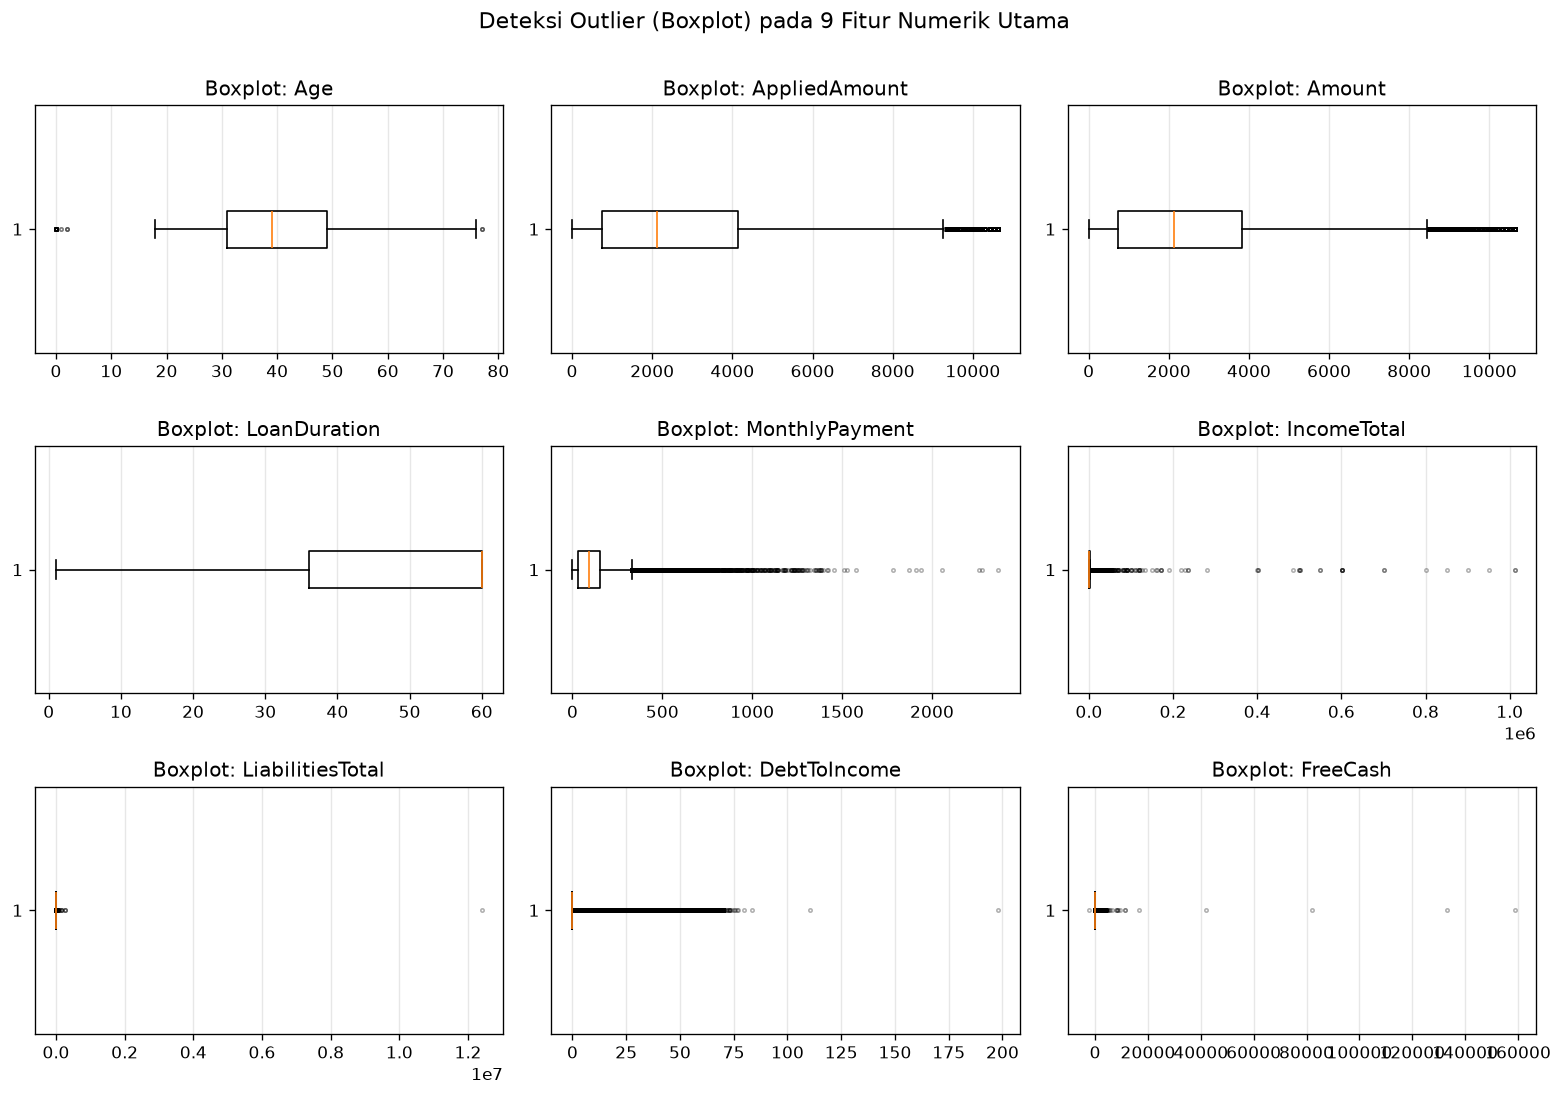

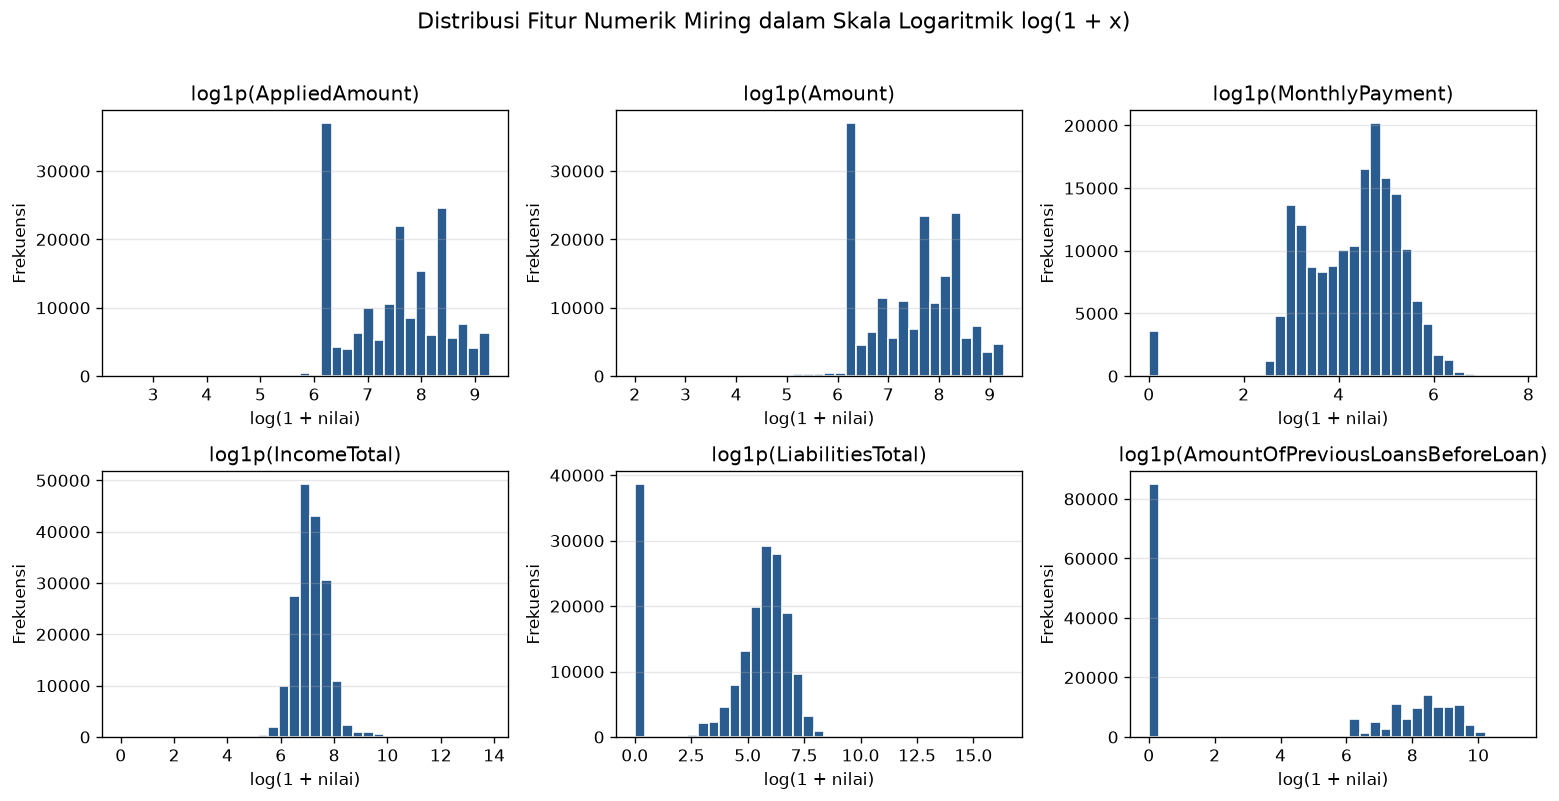

Disimpan ke: reports\tables\outlier_summary.csv (27 kolom numerik fitur Y).
Catatan: Tidak ada outlier yang dihapus atau di-clip pada Tahap 1.

                            nama_kolom  n_valid      min      p01      q1  median      q3        p99         max     iqr  batas_bawah_iqr  batas_atas_iqr  n_outlier_iqr  pct_outlier_iqr  n_di_luar_p01_p99  pct_di_luar_p01_p99
                     CreditScoreEeMini   105097     0.00 600.0000 1000.00 1000.00 1000.00  1000.0000     1000.00    0.00         1000.000        1000.000          24835            23.63                 79                 0.08
                          DebtToIncome   179185     0.00   0.0000    0.00    0.00    0.00    65.4716      198.02    0.00            0.000           0.000          34307            19.15               1792                 1.00
                              FreeCash   179185 -2332.00   0.0000    0.00    0.00    0.00  1284.0000   158748.64    0.00            0.000           0.000          34310          

In [15]:
outlier_df = pd.read_csv(TABLES_DIR / "outlier_summary.csv")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 180):
    print(outlier_df.to_string(index=False))

---
## Bagian F — Fitur Turunan yang Aman (`src/features/basic.py` — Langkah 7)

Menghitung 4 fitur rasio (`loan_to_income_ratio`, `monthly_payment_to_income_ratio`, `total_liabilities_to_income_ratio`, `avg_previous_loan_amount`) dan 3 kolom analisis/pembagi waktu (`funded_to_applied_ratio`, `loan_year`, `loan_month`), serta memverifikasi 5 contoh perhitungan manual.

In [16]:
from src.features.basic import add_basic_derived_features

df = add_basic_derived_features(df)
sample_idx = [0, 1, 2, 10, 25]
with pd.option_context("display.max_columns", 20, "display.width", 190):
    print(df.loc[sample_idx, [
        "LoanId", "AppliedAmount", "Amount", "MonthlyPayment", "IncomeTotal",
        "LiabilitiesTotal", "NoOfPreviousLoansBeforeLoan", "AmountOfPreviousLoansBeforeLoan",
        "LoanDate", "loan_to_income_ratio", "monthly_payment_to_income_ratio",
        "total_liabilities_to_income_ratio", "avg_previous_loan_amount",
        "funded_to_applied_ratio", "loan_year", "loan_month"
    ]].to_string())

=== 5 Contoh Perhitungan Manual Fitur Turunan (Langkah 7) ===
Rumus:
  1. loan_to_income_ratio            = AppliedAmount / IncomeTotal
  2. monthly_payment_to_income_ratio = MonthlyPayment / IncomeTotal
  3. total_liabilities_to_income_ratio = LiabilitiesTotal / IncomeTotal
  4. avg_previous_loan_amount        = AmountOfPreviousLoansBeforeLoan / NoOfPreviousLoansBeforeLoan (0.0 jika 0/0)
  5. funded_to_applied_ratio         = Amount / AppliedAmount (peran: analisis, bukan fitur)
  6. loan_year, loan_month           = tahun & bulan dari LoanDate (peran: pembagi_waktu, bukan fitur)

                                  LoanId  AppliedAmount  Amount  MonthlyPayment  IncomeTotal  LiabilitiesTotal  NoOfPreviousLoansBeforeLoan  AmountOfPreviousLoansBeforeLoan   LoanDate  loan_to_income_ratio  monthly_payment_to_income_ratio  total_liabilities_to_income_ratio  avg_previous_loan_amount  funded_to_applied_ratio  loan_year  loan_month
0   66AE108B-532B-4BB3-BAB7-0019A46412C1         2125.0  2125.0

---
## Bagian G — Eksekusi `build_clean_dataset()` & Verifikasi `bondora_clean.parquet` dan `schema.json` (Langkah 8)

Memanggil `build_clean_dataset()` dari `src.data.build_clean` untuk menjalankan seluruh alur pembersihan data Tahap 1, menyimpan `data/processed/bondora_clean.parquet` (`179.235` baris $\times$ `126` kolom) dan `data/processed/schema.json`, lalu memverifikasi `default.notna().sum() == 113.560` dan `default.sum() == 71.864`.

In [17]:
import json
from src.config import DATA_PROCESSED
from src.data.build_clean import build_clean_dataset

df_reloaded = build_clean_dataset()
with open(DATA_PROCESSED / "schema.json", encoding="utf-8") as f:
    schema_meta = json.load(f)
n_dt_rel = sum(1 for c in df_reloaded.columns if pd.api.types.is_datetime64_any_dtype(df_reloaded[c]))
n_cat_rel = sum(1 for c in df_reloaded.columns if isinstance(df_reloaded[c].dtype, pd.CategoricalDtype))
assert int(df_reloaded["default"].notna().sum()) == 113_560
assert int(df_reloaded["default"].sum()) == 71_864
print(f"Dimensi muat ulang: {df_reloaded.shape[0]:,} baris x {df_reloaded.shape[1]} kolom")
print(f"Verifikasi tipe data: datetime64 = {n_dt_rel}, category = {n_cat_rel}, default dtype = {df_reloaded['default'].dtype}")
print(f"Verifikasi default: notna().sum() = {int(df_reloaded['default'].notna().sum()):,}, sum() = {int(df_reloaded['default'].sum()):,}")
print(f"Jumlah fitur siap pakai (boleh_jadi_fitur == 'Y'): {schema_meta['n_features_Y']}")

[load_raw] Successfully loaded 'LoanData.csv' using encoding='utf-8' (shape=179,235 rows x 112 cols).
File Parquet : data\processed\bondora_clean.parquet (34.82 MB)
File Schema  : data\processed\schema.json
Dimensi      : 179,235 baris x 126 kolom
Verifikasi muat ulang: baris & kolom cocok 100%, kolom datetime64 = 17, kolom category = 15
Verifikasi target default (Int8): default.notna().sum() = 113,560, default.sum() = 71,864, default.isna().sum() = 65,675

=== Distribusi Kolom di bondora_clean.parquet berdasarkan Peran (schema.json) ===
fitur               47
pasca_pinjaman      25
tanggal             16
benchmark           11
flag                 6
identifier           3
sinyal_investor      3
pembagi_waktu        3
missing_tinggi       3
hasil_target         3
target               2
atribut_sensitif     1
pricing              1
flag_censoring       1
analisis             1

=== Distribusi boleh_jadi_fitur di bondora_clean.parquet (126 Kolom) ===
N    79
Y    47 (40 fitur asli + 3 in

---
## Bagian H — Log Pembersihan Data (`cleaning_log.csv` — Langkah 9)

Menampilkan seluruh catatan transformasi dari Langkah 3 hingga Langkah 8 yang tersimpan pada `reports/tables/cleaning_log.csv`.

In [18]:
cleaning_log_df = pd.read_csv(TABLES_DIR / "cleaning_log.csv")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200, "display.max_colwidth", 110):
    print(cleaning_log_df.to_string(index=False))

Disimpan ke: reports\tables\cleaning_log.csv

=== Tabel Lengkap cleaning_log.csv ===
 urutan                                                                                                                                         langkah  baris_sebelum  baris_sesudah  kolom_sebelum  kolom_sesudah  jumlah_nilai_diubah                                                                                                                                                                                                                                                                                                                  alasan
      1                                                        Langkah 3: Pembentukan kolom target (default [Int8 nullable], is_resolved, return_ratio)         179235         179235            112            115               537705 Target default (Int8): 1 jika DefaultDate terisi (71.416) atau Repaid tanpa DefaultDate dgn PrincipalWriteOffs>0 (448), 0 untuk Repaid ta